# Customer Churn Prediction System
**Sqrock IT Solutions — Data Science Internship, Phase 1, Task 4**

**Goal:** predict whether a telecom customer will **churn** (leave) so the company can act before it loses them.

**Dataset:** IBM *Telco Customer Churn* (the same dataset as the popular Kaggle version). It has 7,043 customers and 21 columns covering demographics, services, contract, billing and the target column `Churn`.

**Pipeline:** Data collection → Preprocessing → EDA → Feature engineering → Models (Logistic Regression, Decision Tree, Random Forest, KNN) → Evaluation (Accuracy, Precision, Recall, F1, Confusion Matrix)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

import churn_model as cm  # shared pipeline code, also used by the web app

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
PALETTE = {"No": "#2a6fdb", "Yes": "#e8590c", 0: "#2a6fdb", 1: "#e8590c"}

## 1. Data collection

In [2]:
raw = cm.load_raw()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data preprocessing
### 2.1 Missing values and data types
`TotalCharges` is stored as **text**. It has 11 blank values, all for customers with `tenure = 0` who haven't been billed yet, so I convert it to a number and fill those blanks with 0.

In [4]:
blank = raw["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum(), "| their tenure values:", raw.loc[blank, "tenure"].unique())
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate customer IDs:", raw["customerID"].duplicated().sum())

df = cm.clean(raw)          # numeric TotalCharges, blanks → 0, Churn Yes/No → 1/0
print("Missing values after cleaning:", int(df.isna().sum().sum()))
df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].describe()

Blank TotalCharges: 11 | their tenure values: [0]
Duplicate rows: 0 | duplicate customer IDs: 0
Missing values after cleaning: 0


,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


## 3. Exploratory Data Analysis
### 3.1 Churn distribution: how many left vs stayed?

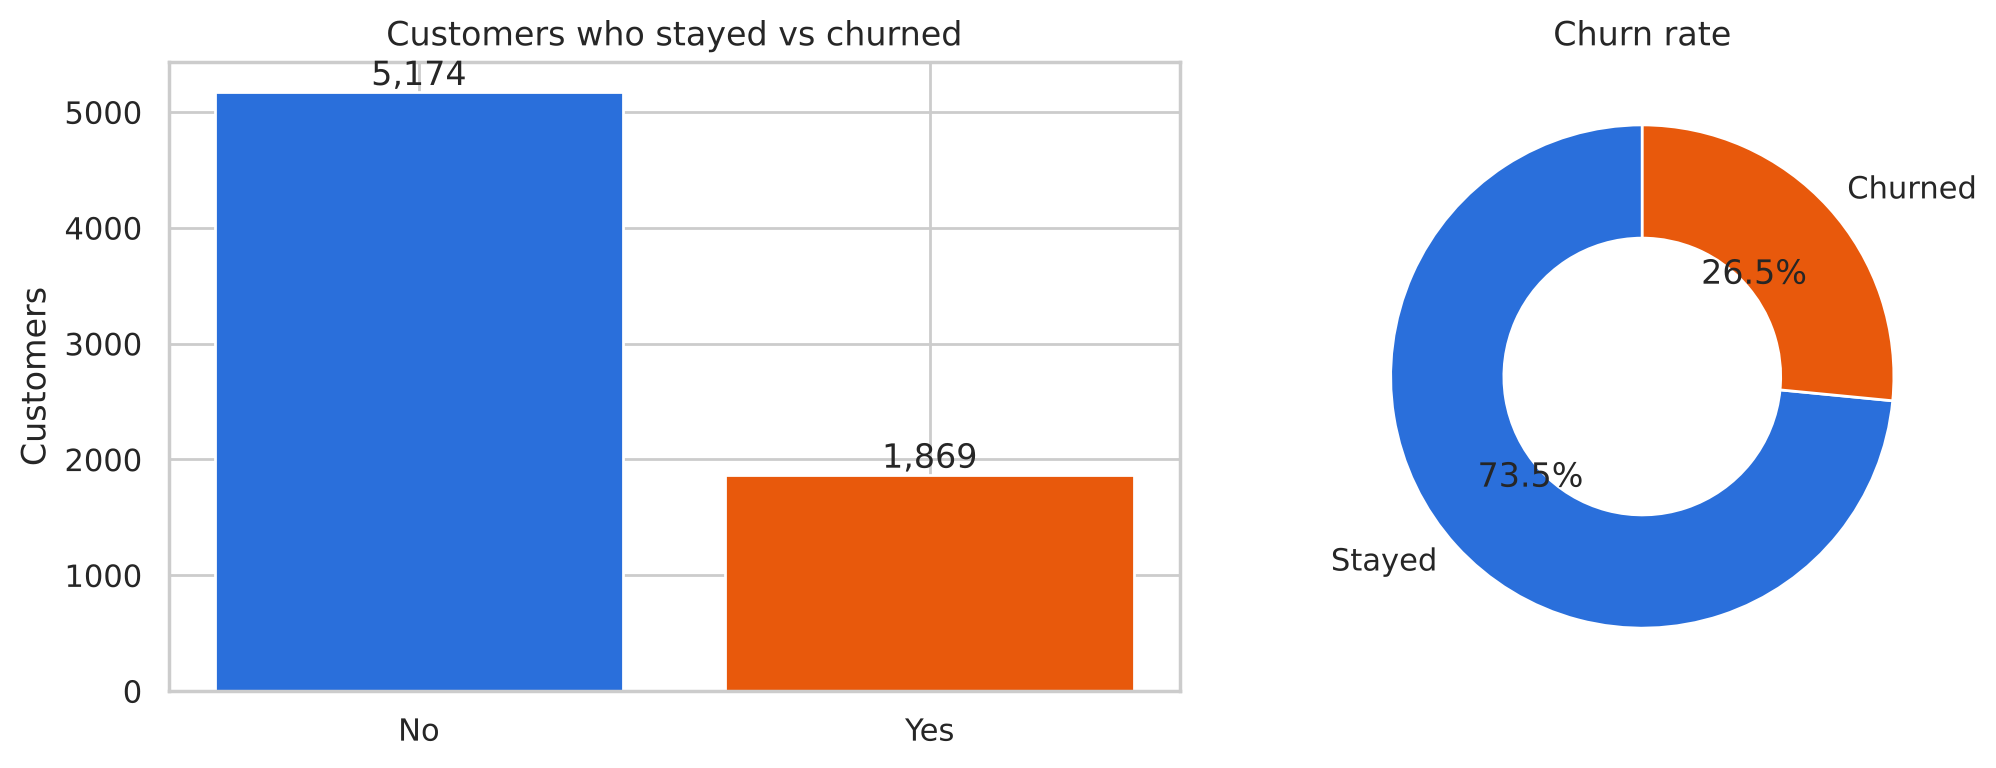

In [5]:
eda = raw.assign(TotalCharges=df["TotalCharges"])
counts = eda["Churn"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
axes[0].set(title="Customers who stayed vs churned", ylabel="Customers")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v:,}", ha="center")
axes[1].pie(counts.values, labels=["Stayed", "Churned"], autopct="%1.1f%%",
            colors=[PALETTE["No"], PALETTE["Yes"]], startangle=90, wedgeprops={"width": 0.45})
axes[1].set_title("Churn rate")
plt.tight_layout()
plt.show()

About **26.5%** of customers churned, so the classes are **imbalanced**. Accuracy alone would be misleading: a model that always says "No churn" would score 73.5%. I'll focus on **recall** and **F1** for the churn class.

### 3.2 Monthly charges vs churn

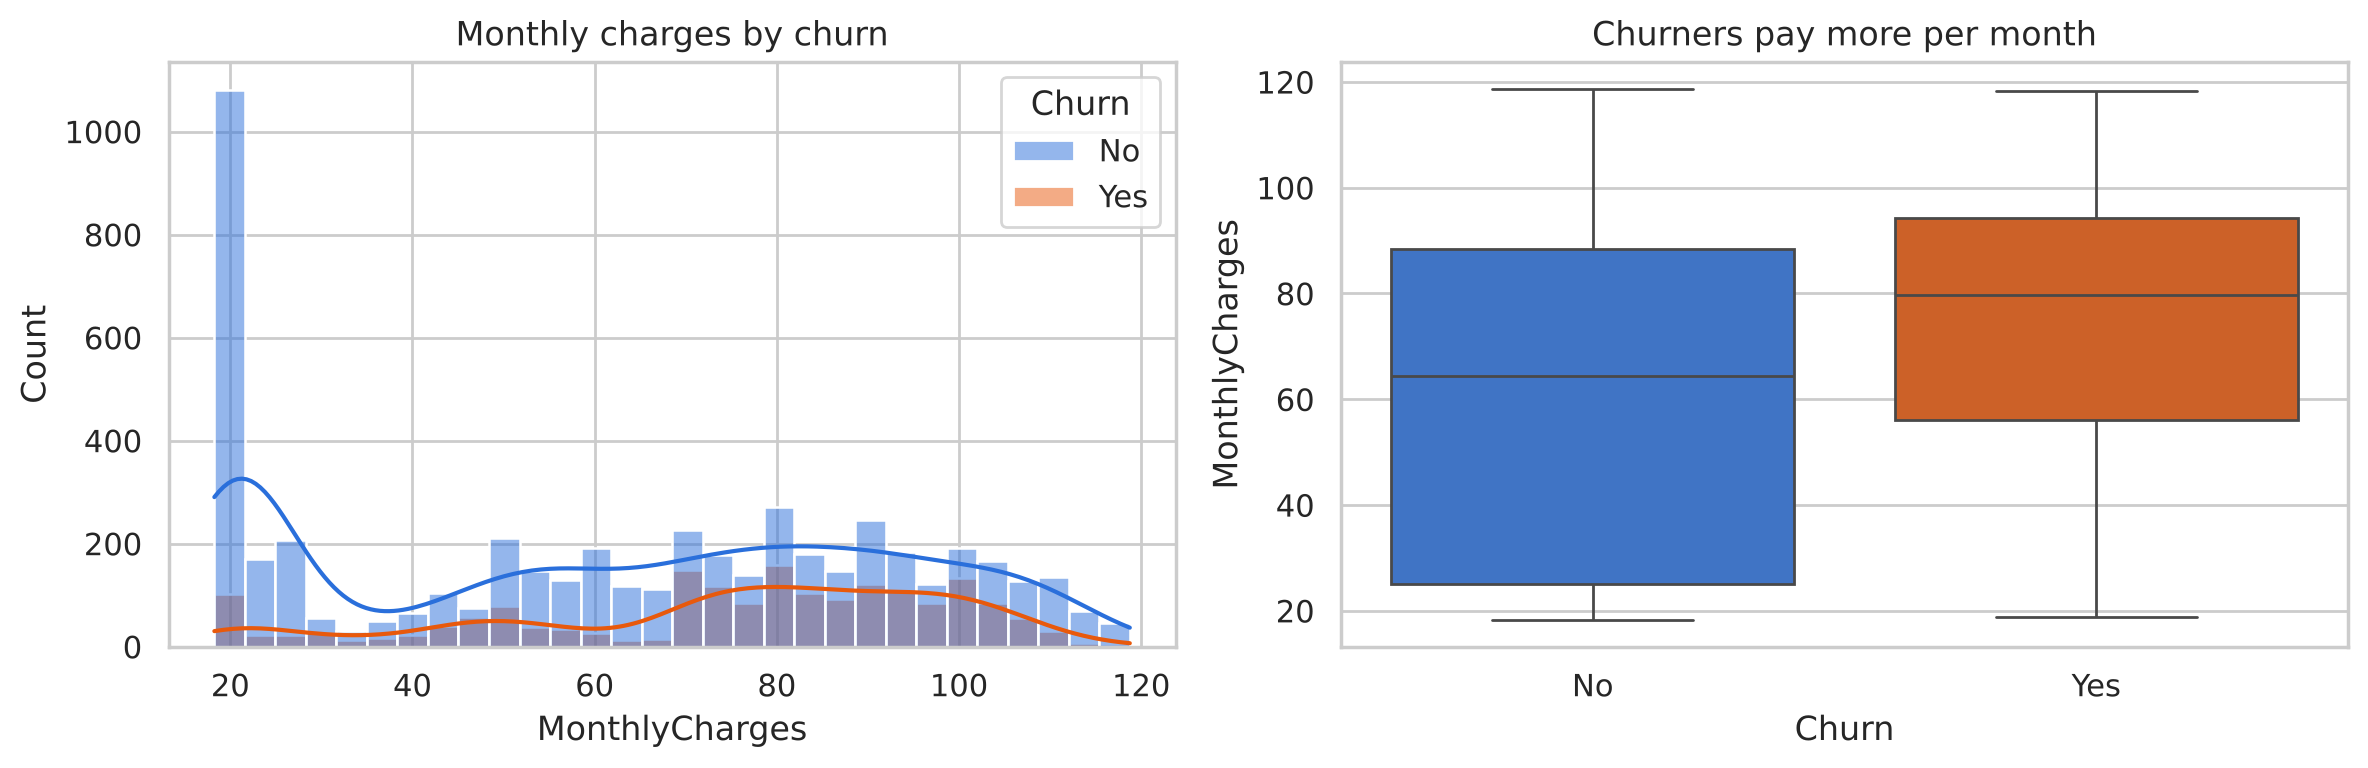

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="MonthlyCharges", hue="Churn", bins=30, kde=True, palette=PALETTE, ax=axes[0])
axes[0].set_title("Monthly charges by churn")
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", palette=PALETTE, ax=axes[1])
axes[1].set_title("Churners pay more per month")
plt.tight_layout()
plt.show()
eda.groupby("Churn")["MonthlyCharges"].mean().round(2)

### 3.3 Tenure vs churn

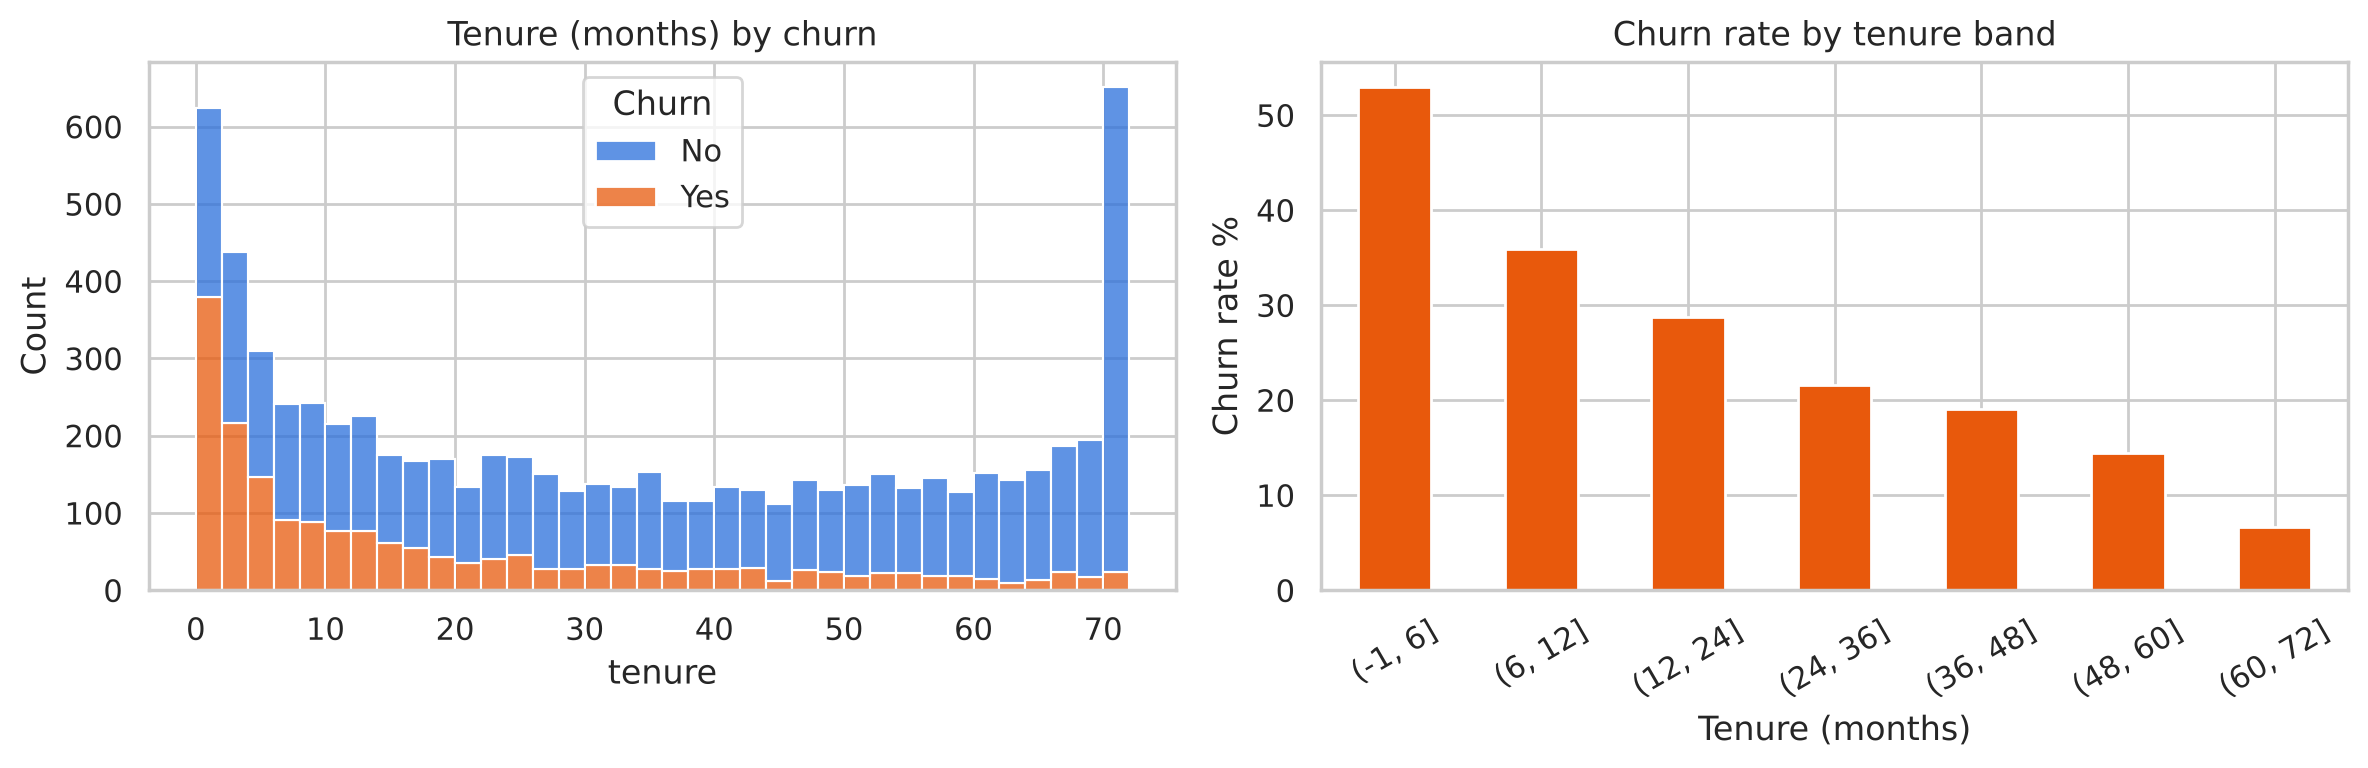

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="tenure", hue="Churn", bins=36, palette=PALETTE, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure (months) by churn")
tenure_rate = eda.groupby(pd.cut(eda["tenure"], [-1, 6, 12, 24, 36, 48, 60, 72]))["Churn"] \
    .apply(lambda s: (s == "Yes").mean() * 100)
tenure_rate.plot(kind="bar", color="#e8590c", ax=axes[1])
axes[1].set(title="Churn rate by tenure band", ylabel="Churn rate %", xlabel="Tenure (months)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

New customers are by far the most likely to leave. Churn falls steadily with tenure.

### 3.4 Contract, internet service and payment method

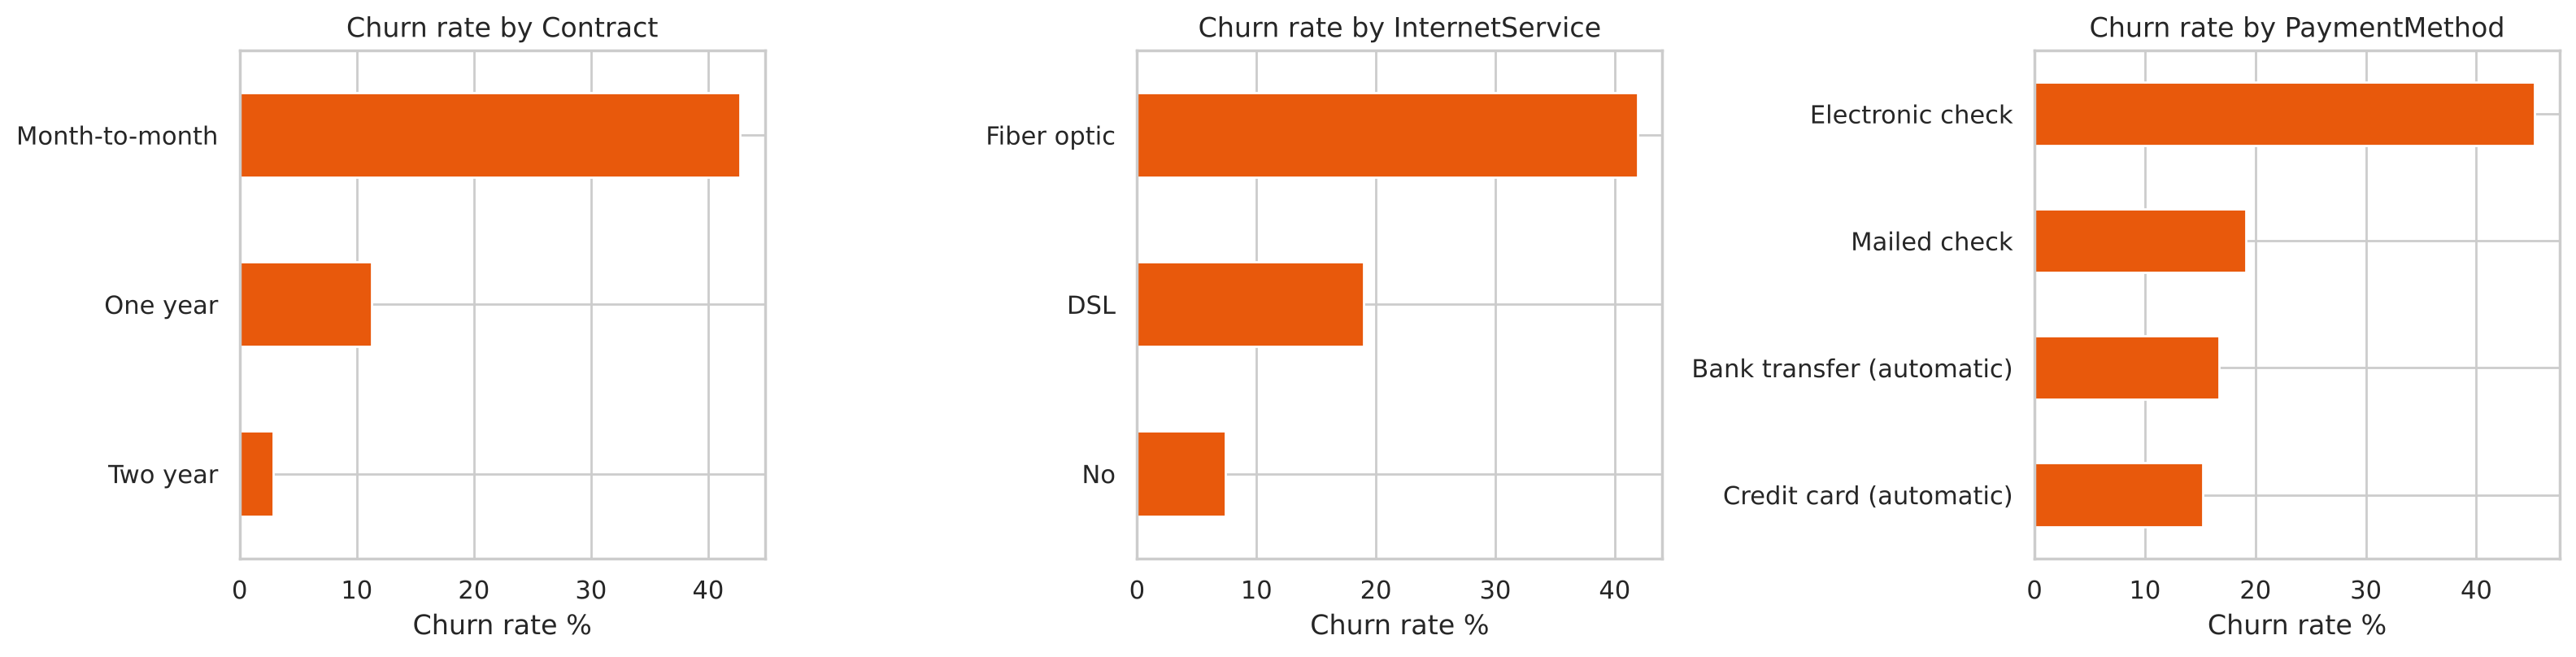

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = eda.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values()
    rate.plot(kind="barh", color="#e8590c", ax=ax)
    ax.set(title=f"Churn rate by {col}", xlabel="Churn rate %", ylabel="")
plt.tight_layout()
plt.show()

### 3.5 Correlation heatmap

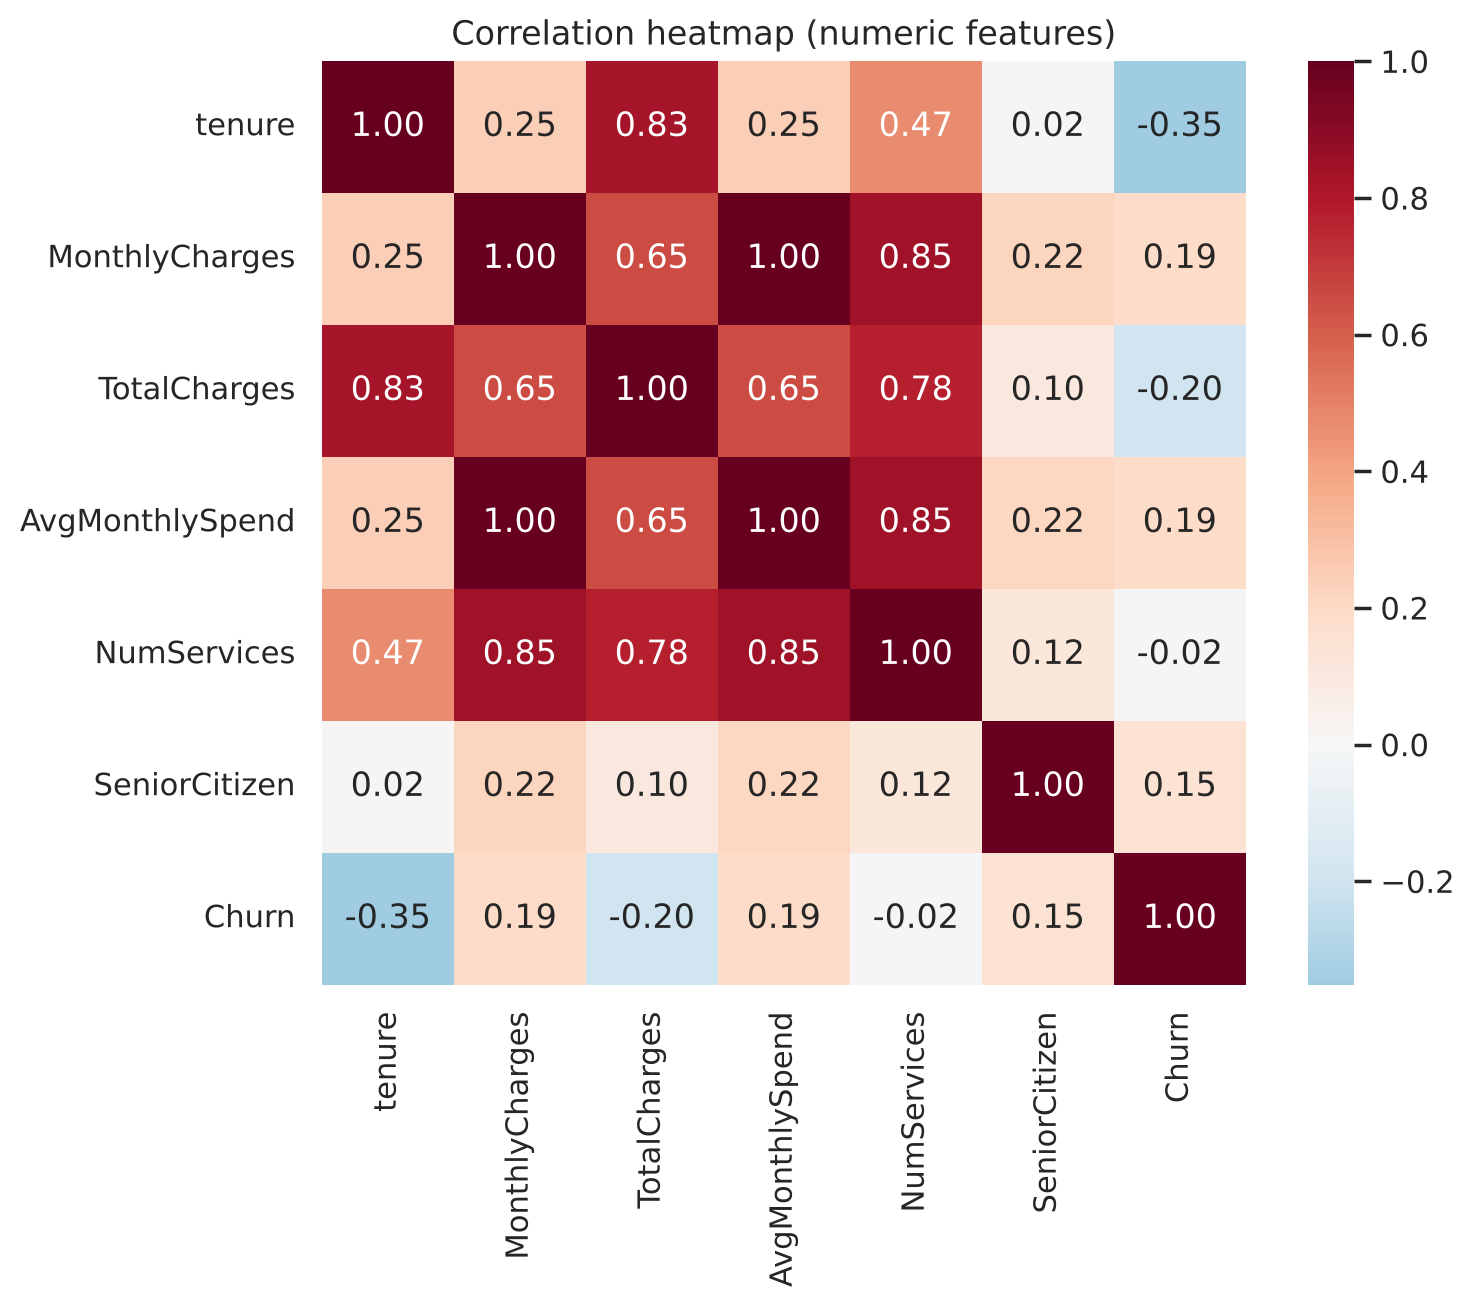

In [9]:
corr_df = cm.engineer(df)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "NumServices", "SeniorCitizen", "Churn"]
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation heatmap (numeric features)")
plt.show()

**EDA takeaways**
- **Month-to-month** contracts churn at about 43%, versus about 3% for two-year contracts. Contract type is the strongest signal.
- Customers in their **first year** and customers with **fiber optic** internet or **electronic check** payments churn the most.
- Churners pay higher monthly charges, but tenure is negatively correlated with churn (-0.35).

## 4. Feature engineering
New features:
- **AvgMonthlySpend** = TotalCharges ÷ tenure (the actual average bill over the customer's lifetime)
- **ContractGroup**: Month-to-month → *Short-term*, one or two years → *Long-term*
- **NumServices**: how many add-on services the customer uses
- **TenureGroup**: 0-12, 13-24, 25-48 or 49-72 months

I also remove `customerID`, which is an identifier with no predictive value.

In [10]:
data = cm.engineer(df)
data[["tenure", "TotalCharges", "AvgMonthlySpend", "Contract", "ContractGroup", "NumServices", "TenureGroup", "Churn"]].head()

,tenure,TotalCharges,AvgMonthlySpend,Contract,ContractGroup,NumServices,TenureGroup,Churn
0,1,29.85,29.850000,Month-to-month,Short-term,2,0-12 mo,0
1,34,1889.50,55.573529,One year,Long-term,4,25-48 mo,0
2,2,108.15,54.075000,Month-to-month,Short-term,4,0-12 mo,1
3,45,1840.75,40.905556,One year,Long-term,4,25-48 mo,0
4,2,151.65,75.825000,Month-to-month,Short-term,2,0-12 mo,1


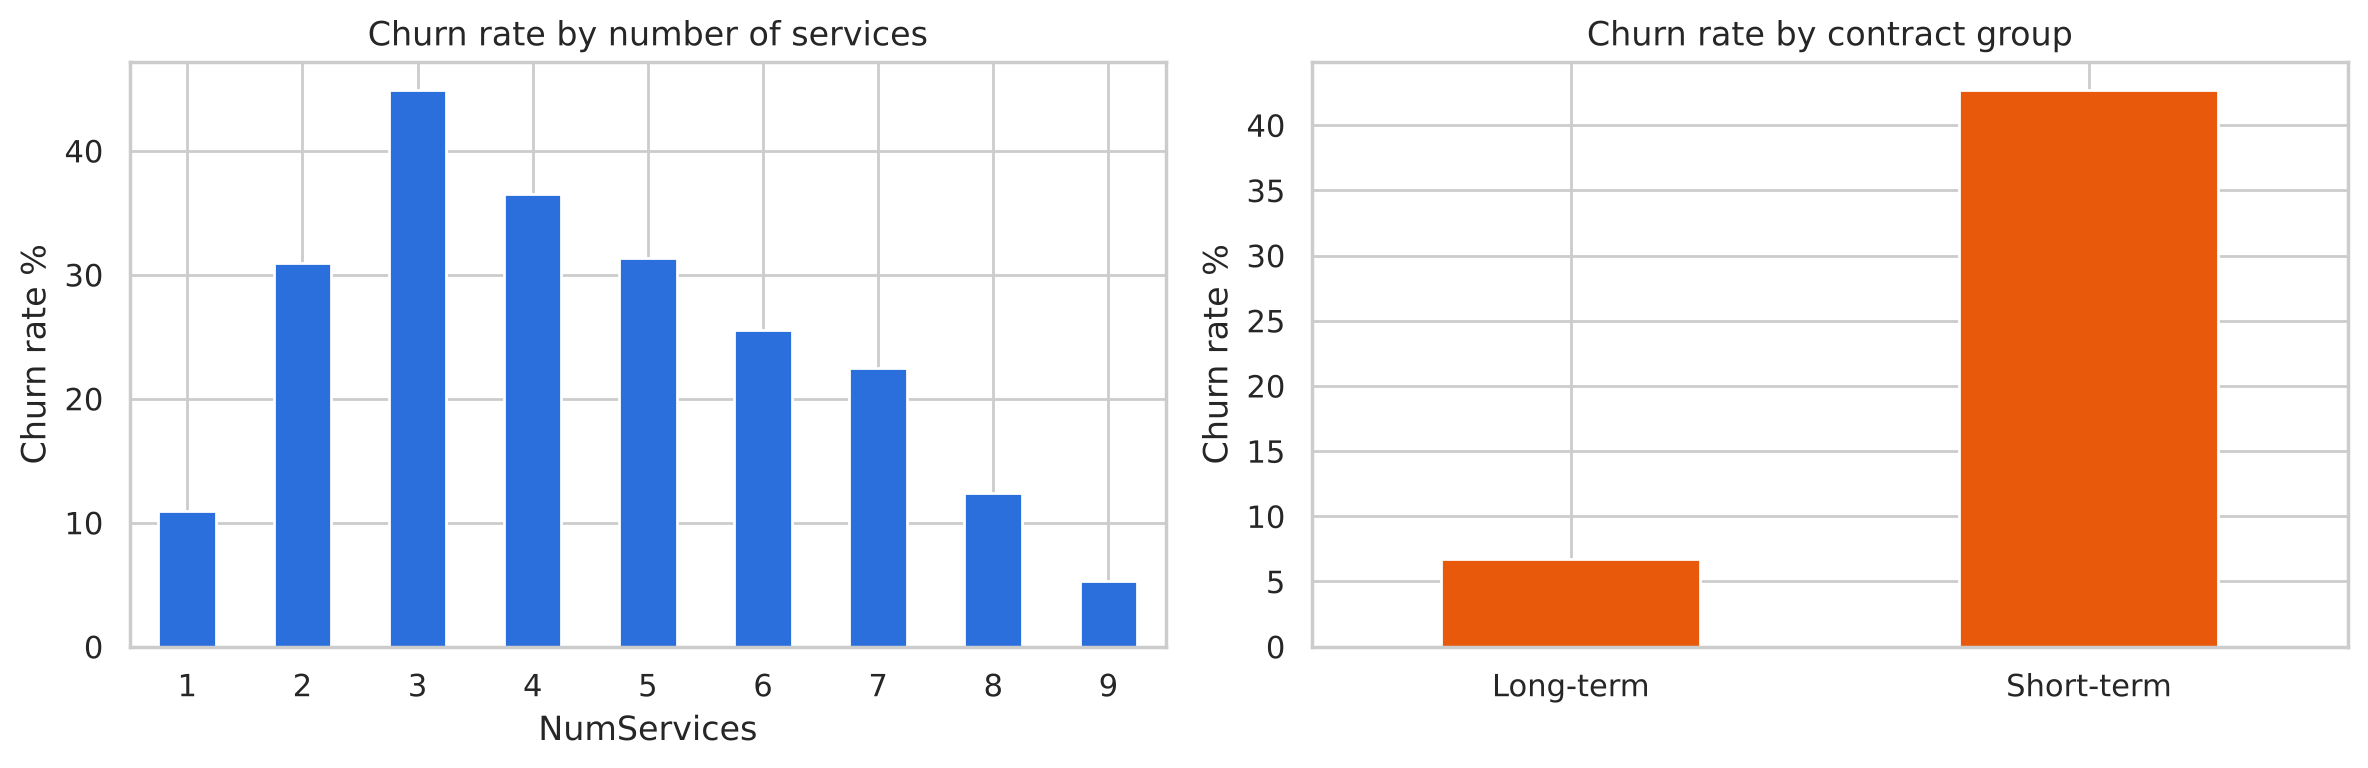

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data.groupby("NumServices")["Churn"].mean().mul(100).plot(kind="bar", color="#2a6fdb", ax=axes[0])
axes[0].set(title="Churn rate by number of services", ylabel="Churn rate %")
data.groupby("ContractGroup")["Churn"].mean().mul(100).plot(kind="bar", color="#e8590c", ax=axes[1])
axes[1].set(title="Churn rate by contract group", ylabel="Churn rate %", xlabel="")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Encoding, scaling and train-test split
- **Categorical → numeric:** one-hot encoding. Yes/No columns become a single 0/1 column.
- **Scaling:** `StandardScaler` on numeric columns. This matters for Logistic Regression and KNN.
- **Split:** 80% train and 20% test, **stratified** so both sets keep the 26.5% churn rate.

Everything lives in one scikit-learn `Pipeline`, so the encoder and scaler only learn from training data (no leakage).

In [12]:
X_train, X_test, y_train, y_test = cm.split(data)
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.1%}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.1%}")
prep = cm.preprocessor().fit(X_train)
print("Features after encoding:", len(prep.get_feature_names_out()))

Train: (5634, 23), churn rate 26.5%
Test:  (1409, 23), churn rate 26.5%
Features after encoding: 47


## 5. Model building
Four classifiers: **Logistic Regression** (baseline), **Decision Tree**, **Random Forest** (recommended) and **KNN**.

Because churners are the minority, the tree models and Logistic Regression use `class_weight="balanced"`. This makes missing a churner count more, which is what the business cares about.

In [13]:
fitted, metrics, cms, _ = cm.train_all(data)
metrics.style.format("{:.3f}").highlight_max(color="#d3f9d8")

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Logistic Regression,0.733,0.498,0.791,0.612,0.842
Decision Tree,0.735,0.500,0.791,0.613,0.829
Random Forest,0.758,0.530,0.786,0.633,0.842
KNN,0.788,0.601,0.599,0.600,0.828


### Why class weighting? A quick comparison
The same Random Forest **without** class weights looks more accurate but misses far more churners:

In [14]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
plain_rf = Pipeline([("prep", cm.preprocessor()),
                     ("model", RandomForestClassifier(n_estimators=400, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1))])
plain_rf.fit(X_train, y_train)
p = plain_rf.predict(X_test)
pd.DataFrame({
    "RF (no class weights)": [accuracy_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)],
    "RF (balanced)": metrics.loc["Random Forest", ["Accuracy", "Recall", "F1 Score"]].values,
}, index=["Accuracy", "Recall", "F1 Score"]).round(3)

,RF (no class weights),RF (balanced)
Accuracy,0.801,0.758
Recall,0.516,0.786
F1 Score,0.579,0.633


The balanced model catches about **79% of churners** instead of about 50%, at the cost of a few points of accuracy. For retention, missing a churner (a lost customer) costs much more than sending an unnecessary discount offer.

## 6. Model evaluation
### 6.1 Metrics comparison

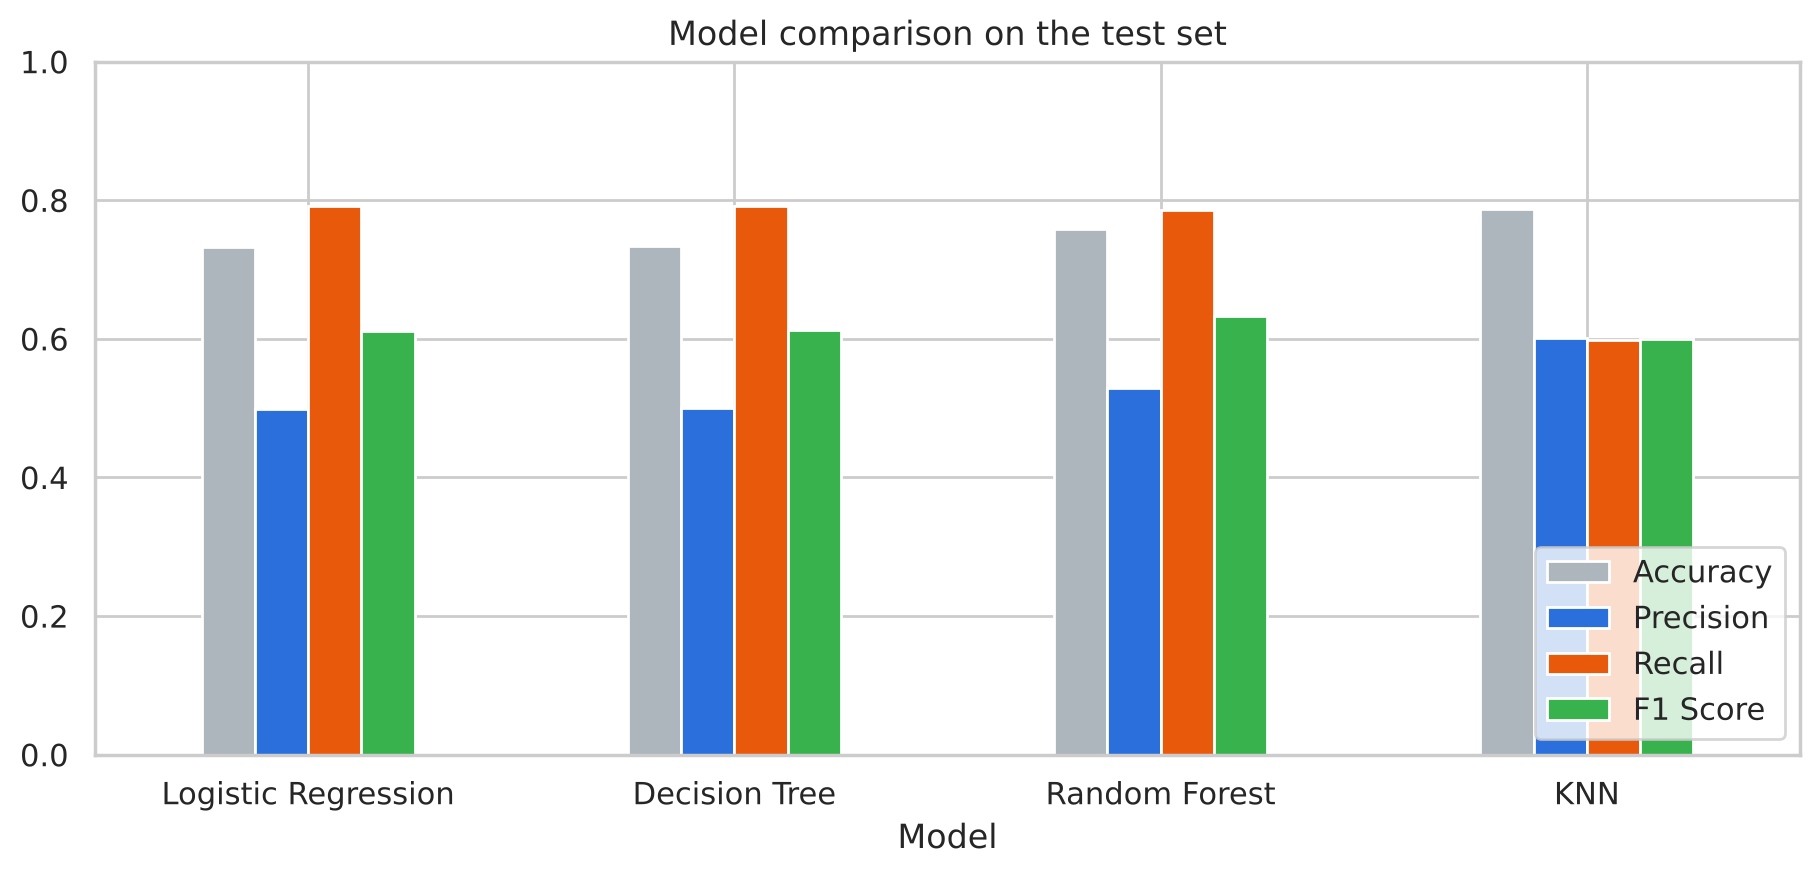

In [15]:
ax = metrics[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(11, 4.5), rot=0,
                                                                   color=["#adb5bd", "#2a6fdb", "#e8590c", "#37b24d"])
ax.set(title="Model comparison on the test set", ylim=(0, 1))
ax.legend(loc="lower right")
plt.show()

### 6.2 Confusion matrices

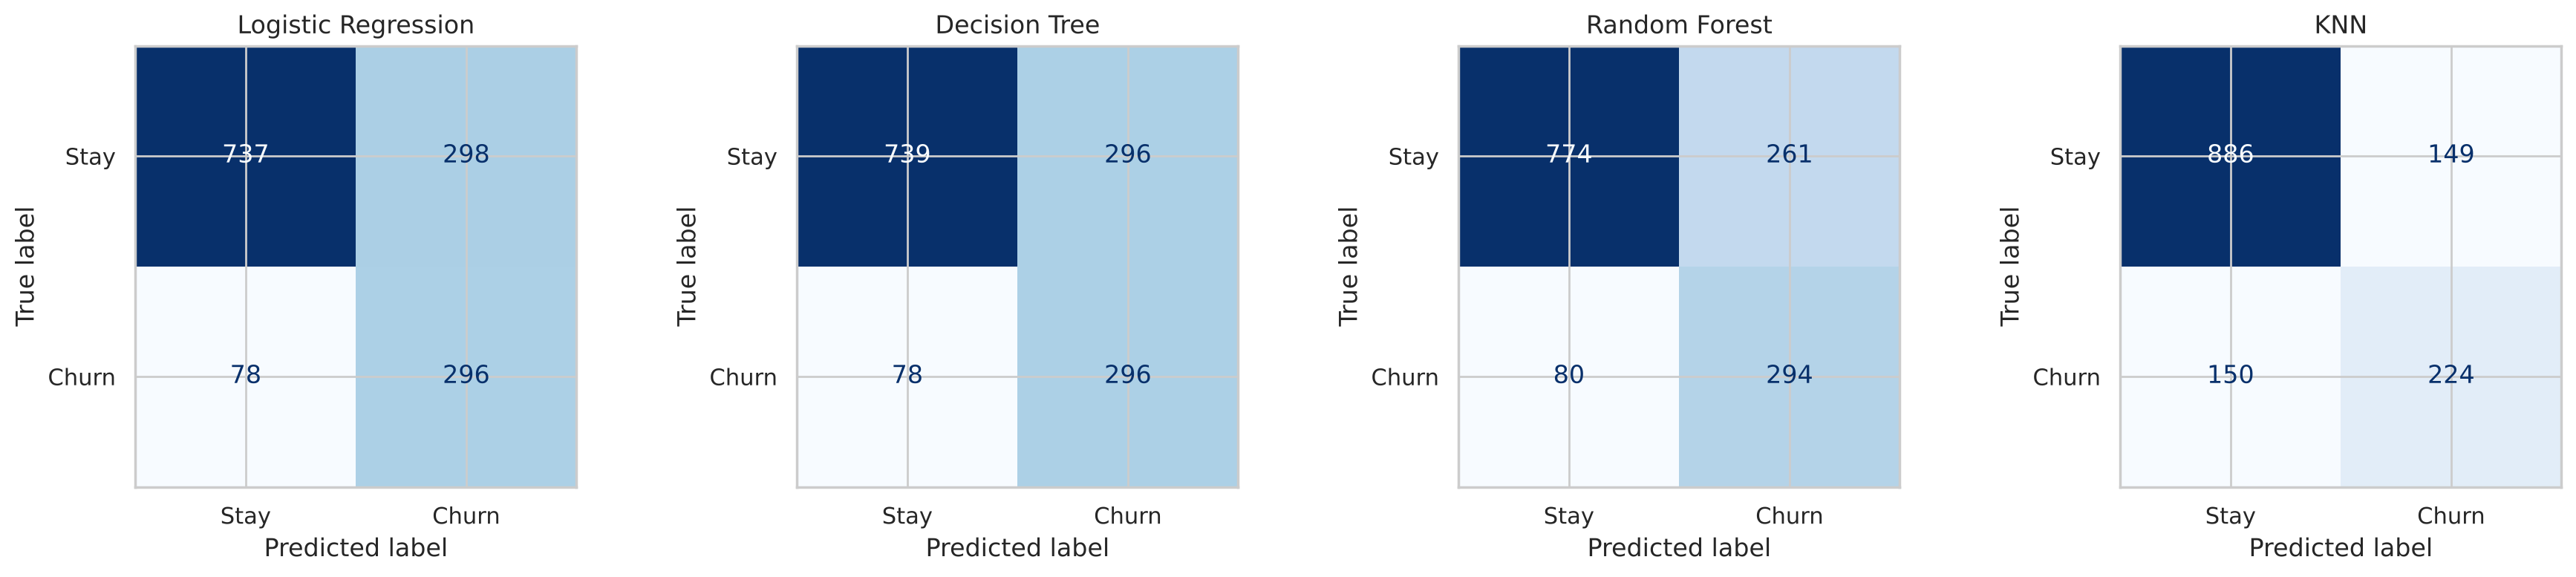

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(m, display_labels=["Stay", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 6.3 ROC curves

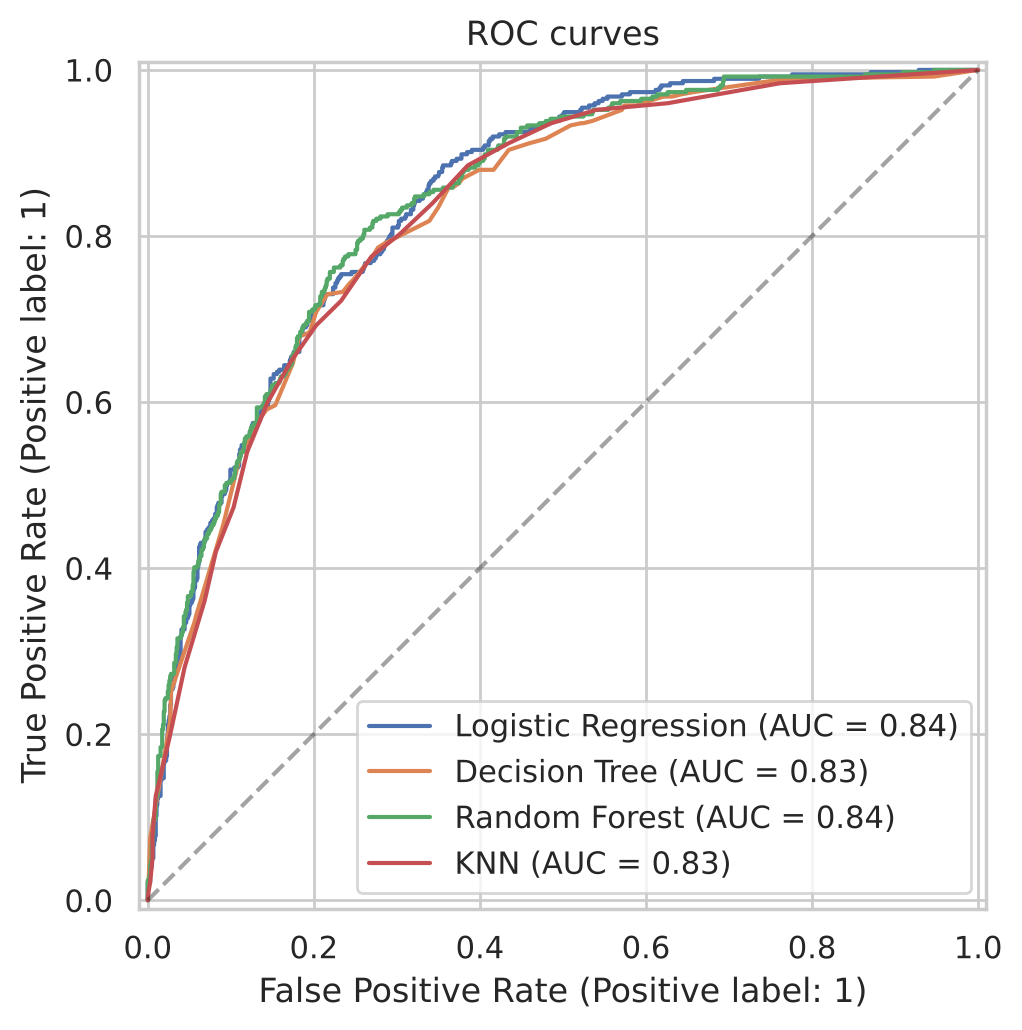

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves")
plt.show()

### 6.4 Best model: Random Forest

              precision    recall  f1-score   support

        Stay       0.91      0.75      0.82      1035
       Churn       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



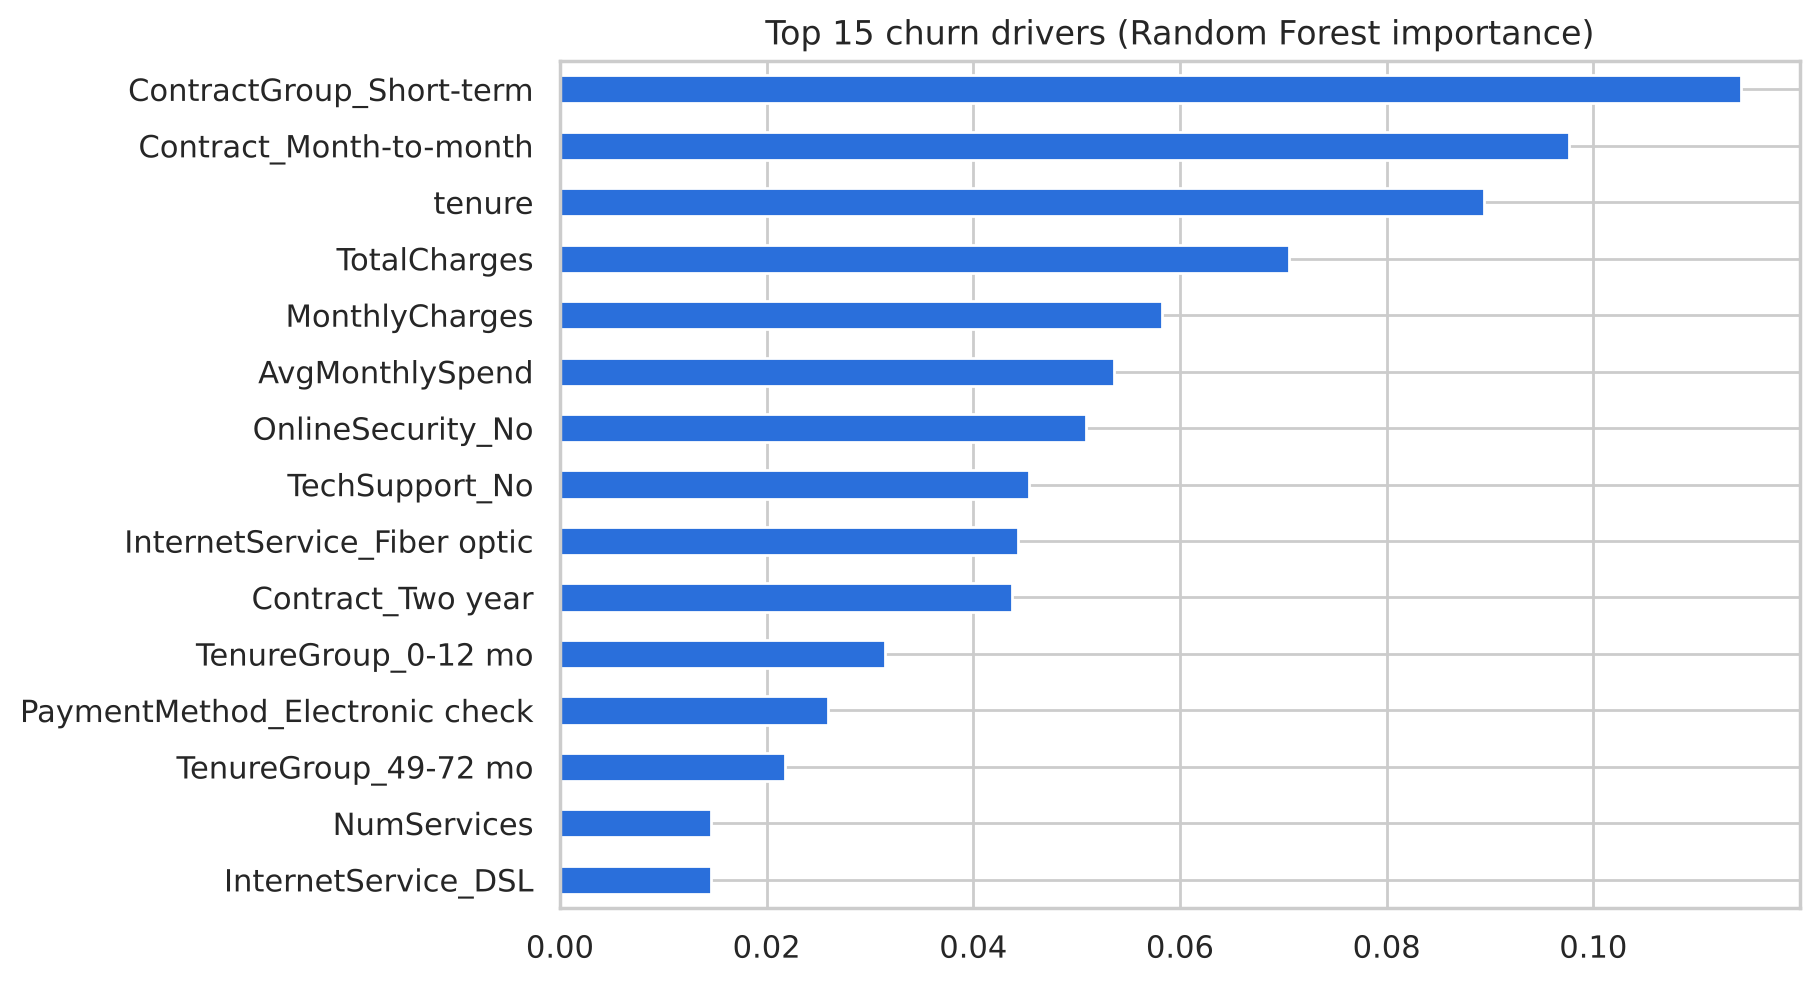

In [18]:
best = fitted["Random Forest"]
print(classification_report(y_test, best.predict(X_test), target_names=["Stay", "Churn"]))

cm.feature_importance(best).head(15)[::-1].plot(kind="barh", color="#2a6fdb", figsize=(8, 5.5))
plt.title("Top 15 churn drivers (Random Forest importance)")
plt.show()

### 6.5 Example: scoring individual customers

In [19]:
sample = X_test.head(8).copy()
sample["Churn probability"] = best.predict_proba(sample)[:, 1].round(3)
sample["Predicted"] = np.where(sample["Churn probability"] >= 0.5, "Churn", "Stay")
sample["Actual"] = y_test.head(8).map({1: "Churn", 0: "Stay"}).values
sample[["tenure", "Contract", "InternetService", "MonthlyCharges", "Churn probability", "Predicted", "Actual"]]

,tenure,Contract,InternetService,MonthlyCharges,Churn probability,Predicted,Actual
437,72,Two year,Fiber optic,114.05,0.037,Stay,Stay
2280,8,Month-to-month,Fiber optic,100.15,0.865,Churn,Stay
2235,41,One year,DSL,78.35,0.169,Stay,Stay
4460,18,Month-to-month,Fiber optic,78.20,0.592,Churn,Stay
3761,72,Two year,DSL,82.65,0.063,Stay,Stay
5748,21,Month-to-month,Fiber optic,99.85,0.757,Churn,Stay
3568,21,Month-to-month,Fiber optic,99.15,0.594,Churn,Stay
2976,19,Month-to-month,No,24.10,0.233,Stay,Stay


## 7. Conclusion
- **Random Forest** is the best overall model: **F1 ≈ 0.63, recall ≈ 0.79, ROC AUC ≈ 0.84**. It catches about 4 out of 5 customers who are about to leave.
- Logistic Regression is close behind and easier to explain. KNN has the highest accuracy but misses about 40% of churners.
- The main churn drivers are **month-to-month contracts, short tenure, high monthly charges, fiber optic internet, electronic check payments, and no online security or tech support**.
- **Business actions:** offer discounted 1-year contracts to new month-to-month customers, bundle security and tech support, and target fiber customers in their first 6 months.
- **Next steps:** tune the decision threshold to the cost of a retention offer, try gradient boosting (XGBoost or LightGBM), and use SHAP values to explain individual predictions.